# 06 · Final model (run 6) and neural network

**Run 6 — final model.** DINOv2 whole-photo features + the CDCM overflow helper + the open-bag helper (notebook 05) →
RBF SVM (C = 3, class-balanced). **Training data.** 66 original photos + 39 licensed external photos (notebook 04).
File: `submission_final.csv`.

**Neural network (prepared, not submitted).** The same 2054 input numbers and the same 105 training photos, classified
by the PyTorch MLP (`common.TorchMLP`, seed 0) instead of the SVM. File: `submission_mlp.csv`.

In [1]:
import numpy as np, pandas as pd
import common as c
pd.set_option('display.width', 200)

In [2]:
df = c.training_set(final=True)
X = c.final_features(df.id)
print(len(df), "training rows,", X.shape[1], "numbers per photo")
res, P = c.cross_validate(df, X, list(c.MODELS), name="final")
res

105 training rows, 2054 numbers per photo


,experiment,model,CV macro F1,std,dishes F1,trash F1
0,final,logistic regression,0.895,0.016,0.889,0.904
1,final,RBF SVM,0.912,0.013,0.893,0.931
2,final,extra trees,0.863,0.036,0.862,0.865
3,final,neural net (MLP),0.847,0.027,0.857,0.858


Competition photos the RBF SVM gets wrong (times out of 10):

{'#13': 1, '#26': 10, '#31': 10, '#47': 1, '#48': 1, '#60': 10, '#64': 3, '#77': 10, '#101': 10}


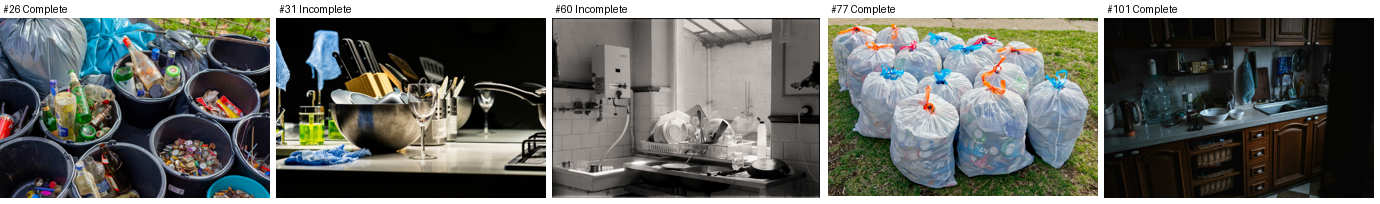

In [3]:
w = c.wrong_counts(df, P["RBF SVM"])
print(w)
ids = [int(k[1:]) for k, v in w.items() if v >= 5]
c.show(ids, [df.set_index("id").label[i].split("|")[1] for i in ids], cols=5)

## Run 6: train the RBF SVM on all 105 photos and predict the 36 test photos

In [4]:
_, test = c.competition()
model = c.MODELS["RBF SVM"]().fit(X, df.y.values)
pred = c.proba(model, c.final_features(test.id)).argmax(1)
sub = pd.DataFrame({"id": test.id, "label": [c.CLASSES[k] for k in pred]})
sub.to_csv("submission_final.csv", index=False)
sub.label.value_counts()

label
Washing Dishes|Incomplete      11
Taking Out Trash|Incomplete     9
Washing Dishes|Complete         8
Taking Out Trash|Complete       8
Name: count, dtype: int64

## Neural network (MLP, not submitted): train it on all 105 photos and predict the 36 test photos

Dropout 0.2 → Linear(2054, 256) → GELU → dropout 0.5 → Linear(256, 4); class-weighted cross-entropy with label
smoothing 0.1, AdamW, cosine learning-rate schedule, 600 steps of batch 32, seed 0. Its CV score is in the table at
the top (row "neural net (MLP)").

In [5]:
mlp = c.MODELS["neural net (MLP)"]().fit(X, df.y.values)
pred_mlp = c.proba(mlp, c.final_features(test.id)).argmax(1)
sub_mlp = pd.DataFrame({"id": test.id, "label": [c.CLASSES[k] for k in pred_mlp]})
sub_mlp.to_csv("submission_mlp.csv", index=False)
print(f"the MLP agrees with run 6 on {(sub_mlp.label.values == sub.label.values).sum()} of {len(sub)} test photos")
sub_mlp.label.value_counts()

the MLP agrees with run 6 on 33 of 36 test photos


label
Washing Dishes|Incomplete      13
Taking Out Trash|Incomplete    10
Taking Out Trash|Complete       7
Washing Dishes|Complete         6
Name: count, dtype: int64

Agreement with earlier submission files (same 36 test photos):

In [6]:
old = {"public 0.94155 (extra trees, run 2)": "best_0.94155/submission_public0.94155_extratrees.csv",
       "run 5 (public 0.88311)": "submissions/submission_dinov2_open_routed.csv"}
rows = []
for name, f in old.items():
    o = pd.read_csv(f).set_index("id").label.reindex(sub.id)
    rows.append({"file": name, "same label": int((o.values == sub.label.values).sum()), "of": len(sub)})
pd.DataFrame(rows)

,file,same label,of
0,"public 0.94155 (extra trees, run 2)",32,36
1,run 5 (public 0.88311),35,36


**Dev scores:** the CV macro F1 in the table at the top is the number to report: RBF SVM ≈ 0.91 for run 6, neural net
(MLP) ≈ 0.85. The public leaderboard covers only part of the test set and was not used to choose the model.